In [1]:
import pandas as pd

df = pd.read_csv("Data/Mall_Customers.csv")
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
df.shape

(200, 5)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Genre                   200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df.isnull().sum()

CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [7]:
# convert categorical string to numarical data

from sklearn.preprocessing import LabelEncoder
ll = LabelEncoder()

df['Genre'] = ll.fit_transform(df['Genre']) # type: ignore

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Genre                   200 non-null    int64
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(5)
memory usage: 7.9 KB


In [9]:
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,1,19,15,39
1,2,1,21,15,81
2,3,0,20,16,6
3,4,0,23,16,77
4,5,0,31,17,40


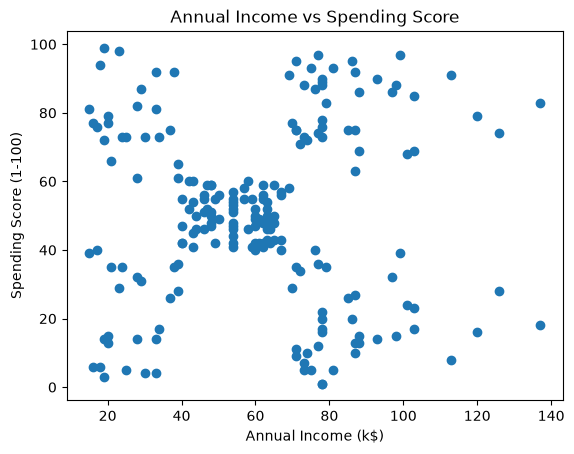

In [10]:
import matplotlib.pyplot as mlt

X = df['Annual Income (k$)']
Y = df['Spending Score (1-100)']

mlt.scatter(X, Y)
mlt.xlabel('Annual Income (k$)')
mlt.ylabel('Spending Score (1-100)')
mlt.title('Annual Income vs Spending Score')
mlt.show()

In [11]:
df.columns

Index(['CustomerID', 'Genre', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='str')

In [12]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
x = df[['Annual Income (k$)', 'Spending Score (1-100)']]
df['Cluster'] = kmeans.fit_predict(x)
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,1,19,15,39,1
1,2,1,21,15,81,0
2,3,0,20,16,6,1
3,4,0,23,16,77,0
4,5,0,31,17,40,1


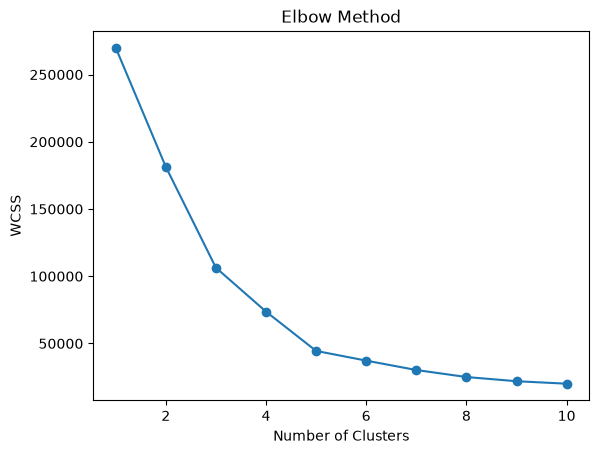

In [ ]:
# Find the optimum number of clusters using the Elbow Method.

wcss = []   # Within-Cluster Sum of Squares

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(x)
    wcss.append(kmeans.inertia_)

mlt.plot(range(1, 11), wcss, marker='o')
mlt.xlabel('Number of Clusters')
mlt.ylabel('WCSS')
mlt.title('Elbow Method')
mlt.show()

In [ ]:
# Silhouette Score for K=2 through K=8. take the highest score value

from sklearn.metrics import silhouette_score

for k in range(2, 9):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(x)

    score = silhouette_score(x, labels)

    print(k, "->", score)

2 -> 0.39564531743995546
3 -> 0.46761358158775435
4 -> 0.4937945814354117
5 -> 0.553931997444648
6 -> 0.5128405328004378
7 -> 0.5017174409749505
8 -> 0.4962769338093321


In [ ]:
# 5 is selected for k number of cluster